# Datheon Internship — Task 3
## Predictive Customer Churn Classifier (Random Forest & XGBoost)

**Objective:** Predict telecom customer churn from subscription records and compare Random Forest and XGBoost.

**Dataset:** IBM Telco Customer Churn CSV (typically 7,043 records).
**Assignment goal:** ROC-AUC > 0.80. This is a target, not a guaranteed result. Report only measured results.

### Workflow
Data loading and validation → cleaning → EDA → stratified split → preprocessing → SMOTE within CV pipelines → Random Forest/XGBoost tuning → test evaluation → ROC/confusion matrices → feature importance → exports.

Run all cells from top to bottom. Hyperparameter search may take several minutes.

## 1. Imports and environment

In [1]:
import os, sys, urllib.request, warnings, importlib.util
warnings.filterwarnings("ignore")
missing=[m for m in ["numpy","pandas","matplotlib","seaborn","sklearn","imblearn","xgboost"] if importlib.util.find_spec(m) is None]
if missing: raise ImportError("Install missing packages with: python -m pip install -r requirements.txt")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay, classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
SEED=42
np.random.seed(SEED); sns.set_theme(style="whitegrid")
print("Python",sys.version.split()[0],"— imports successful")

Python 3.13.1 — imports successful


## 2. Load dataset


In [2]:
DATA_PATH="data/Telco-Customer-Churn.csv"
DATA_URL="https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
if not os.path.isfile(DATA_PATH):
    os.makedirs("data",exist_ok=True)
    try: urllib.request.urlretrieve(DATA_URL,DATA_PATH)
    except Exception as e: raise RuntimeError(f"Download failed. Download {DATA_URL} and save as {DATA_PATH}. Error: {e}")
df=pd.read_csv(DATA_PATH)
print("Shape:",df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Validate and clean data
Convert blank/invalid `TotalCharges` values to numeric missing values; imputation occurs later within the preprocessing pipeline.

In [3]:
required={"Churn","TotalCharges","customerID"}
if not required.issubset(df.columns): raise ValueError(f"Missing expected columns: {required-set(df.columns)}")
print("Duplicates:",df.duplicated().sum())
display(df["Churn"].value_counts(dropna=False).to_frame("count"))
df=df.copy()
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"].astype(str).str.strip(),errors="coerce")
df=df.drop_duplicates().dropna(subset=["Churn"]).reset_index(drop=True)
display(df.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Clean shape:",df.shape)

Duplicates: 0


,count
Churn,
No,5174
Yes,1869


,missing
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


Clean shape: (7043, 21)


## 4. Exploratory data analysis

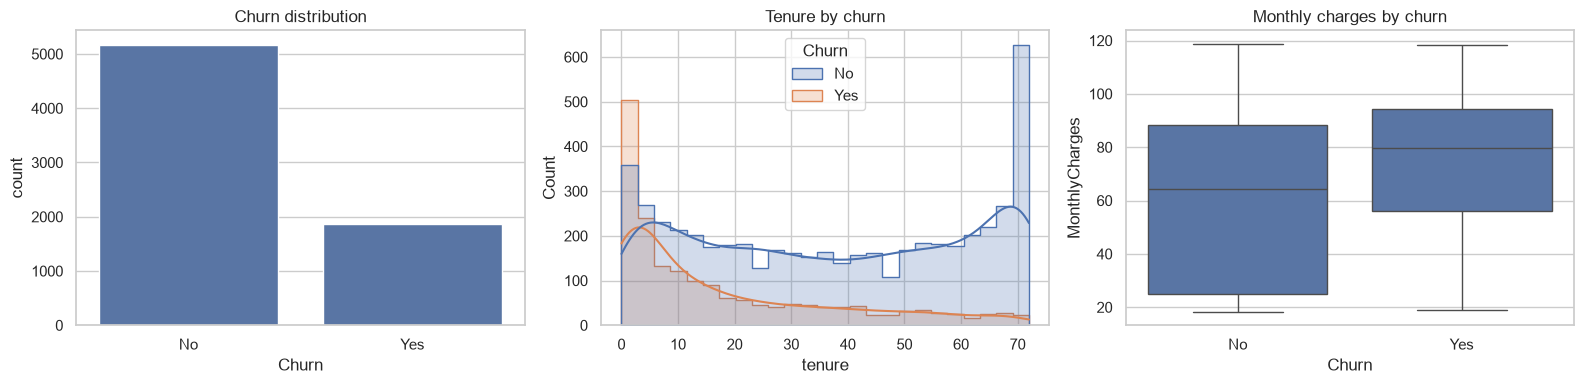

,percentage
Churn,
No,73.463013
Yes,26.536987


In [4]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
sns.countplot(data=df,x="Churn",ax=ax[0]); ax[0].set_title("Churn distribution")
sns.histplot(data=df,x="tenure",hue="Churn",bins=25,kde=True,element="step",ax=ax[1]); ax[1].set_title("Tenure by churn")
sns.boxplot(data=df,x="Churn",y="MonthlyCharges",ax=ax[2]); ax[2].set_title("Monthly charges by churn")
plt.tight_layout(); plt.show()
display((df.Churn.value_counts(normalize=True)*100).rename("percentage").to_frame())

## 5. Target and stratified train/test split
Map No=0 and Yes=1. Exclude `customerID`, which is an identifier rather than a generalizable feature.

In [5]:
y=df["Churn"].map({"No":0,"Yes":1})
if y.isna().any(): raise ValueError("Unexpected Churn labels; expected No and Yes.")
X=df.drop(columns=["Churn","customerID"],errors="ignore")
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
print("Train:",X_train.shape,"Test:",X_test.shape,"Train churn rate:",round(y_train.mean(),4))

Train: (5634, 19) Test: (1409, 19) Train churn rate: 0.2654


## 6. Preprocessing
Numeric features: median imputation and scaling. Categorical features: most-frequent imputation and one-hot encoding. Fitting occurs within each CV fold.

In [6]:
num_cols=X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols=[c for c in X_train.columns if c not in num_cols]
try: encoder=OneHotEncoder(handle_unknown="ignore",sparse_output=False)
except TypeError: encoder=OneHotEncoder(handle_unknown="ignore",sparse=False)
prep=ColumnTransformer([
 ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num_cols),
 ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",encoder)]),cat_cols)
])
print("Numeric:",num_cols,"| categorical count:",len(cat_cols))

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'] | categorical count: 15


## 7. Leakage-safe pipelines and cross-validation
SMOTE is inside the imbalanced-learn pipeline, so synthetic samples are created only from training folds.

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
rf_pipe=ImbPipeline([("prep",prep),("smote",SMOTE(random_state=SEED)),("model",RandomForestClassifier(random_state=SEED,n_jobs=-1))])
xgb_pipe=ImbPipeline([("prep",prep),("smote",SMOTE(random_state=SEED)),("model",XGBClassifier(random_state=SEED,eval_metric="logloss",n_jobs=-1,tree_method="hist"))])

## 8. Random Forest tuning
Randomized search uses stratified 5-fold CV and ROC-AUC scoring. `n_iter=10` balances runtime and parameter exploration.

In [8]:
rf_params={"model__n_estimators":[200,300,500],"model__max_depth":[None,8,12,18],
 "model__min_samples_split":[2,5,10],"model__min_samples_leaf":[1,2,4],"model__max_features":["sqrt",.5]}
rf_search=RandomizedSearchCV(rf_pipe,rf_params,n_iter=10,scoring="roc_auc",cv=cv,random_state=SEED,n_jobs=-1,verbose=1,refit=True)
rf_search.fit(X_train,y_train); best_rf=rf_search.best_estimator_
print("RF CV ROC-AUC:",round(rf_search.best_score_,4)); print(rf_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
RF CV ROC-AUC: 0.8436
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 4, 'model__max_features': 'sqrt', 'model__max_depth': 8}


## 9. XGBoost tuning

In [9]:
xgb_params={"model__n_estimators":[200,300,500],"model__max_depth":[2,3,4,5],
 "model__learning_rate":[.02,.05,.08,.1],"model__subsample":[.7,.85,1.0],
 "model__colsample_bytree":[.7,.85,1.0],"model__min_child_weight":[1,3,5],"model__reg_lambda":[1,3,5]}
xgb_search=RandomizedSearchCV(xgb_pipe,xgb_params,n_iter=10,scoring="roc_auc",cv=cv,random_state=SEED,n_jobs=-1,verbose=1,refit=True)
xgb_search.fit(X_train,y_train); best_xgb=xgb_search.best_estimator_
print("XGBoost CV ROC-AUC:",round(xgb_search.best_score_,4)); print(xgb_search.best_params_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
XGBoost CV ROC-AUC: 0.8464
{'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 500, 'model__min_child_weight': 1, 'model__max_depth': 2, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.85}


## 10. Hold-out test evaluation
The test set is held out until model selection is complete. Metrics use probability threshold 0.50.

In [10]:
models={"Random Forest":best_rf,"XGBoost":best_xgb}
cv_scores={"Random Forest":rf_search.best_score_,"XGBoost":xgb_search.best_score_}
probs={}; preds={}; rows=[]
for name,model in models.items():
    p=model.predict_proba(X_test)[:,1]; pred=(p>=.5).astype(int)
    probs[name]=p; preds[name]=pred
    rows.append({"Model":name,"CV ROC-AUC":cv_scores[name],"Test ROC-AUC":roc_auc_score(y_test,p),
      "Accuracy":accuracy_score(y_test,pred),"Precision":precision_score(y_test,pred,zero_division=0),
      "Recall":recall_score(y_test,pred,zero_division=0),"F1":f1_score(y_test,pred,zero_division=0)})
metrics=pd.DataFrame(rows).sort_values("Test ROC-AUC",ascending=False).reset_index(drop=True)
display(metrics.round(4))
selected_name=metrics.loc[0,"Model"]; print("Best test ROC-AUC model:",selected_name)

,Model,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1
0,XGBoost,0.8464,0.8429,0.7757,0.5668,0.6578,0.6089
1,Random Forest,0.8436,0.8370,0.7658,0.5442,0.7246,0.6216


Best test ROC-AUC model: XGBoost


## 11. ROC curves

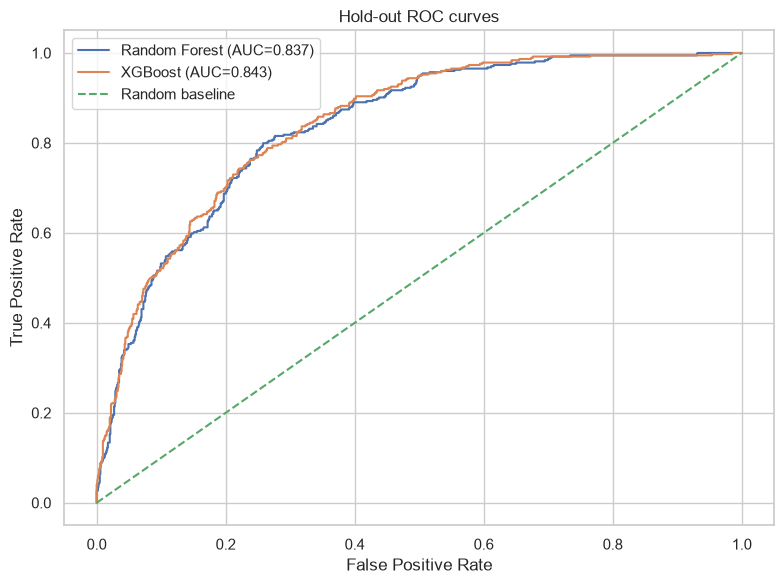

In [11]:
plt.figure(figsize=(8,6))
for name,p in probs.items():
    fpr,tpr,_=roc_curve(y_test,p); plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(y_test,p):.3f})")
plt.plot([0,1],[0,1],"--",label="Random baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Hold-out ROC curves")
plt.legend(); plt.tight_layout(); plt.show()

## 12. Confusion matrices and classification reports

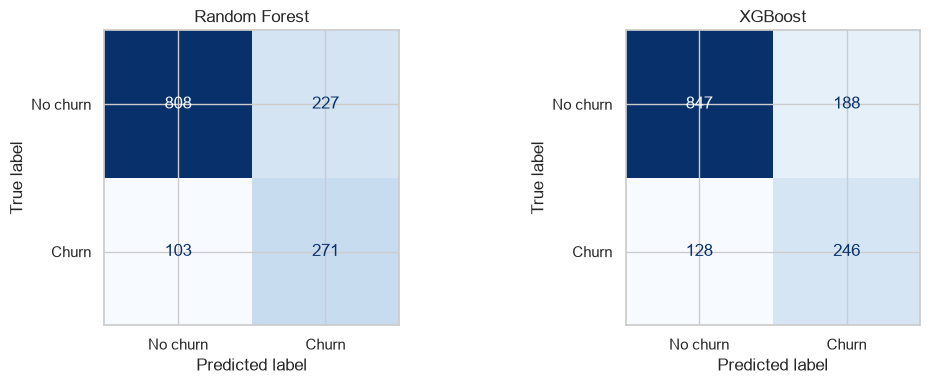

\n Random Forest
              precision    recall  f1-score   support

    No churn       0.89      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.77      1409

\n XGBoost
              precision    recall  f1-score   support

    No churn       0.87      0.82      0.84      1035
       Churn       0.57      0.66      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for a,(name,pred) in zip(axes,preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=["No churn","Churn"],cmap="Blues",colorbar=False,ax=a)
    a.set_title(name)
plt.tight_layout(); plt.show()
for name,pred in preds.items():
    print("\\n",name); print(classification_report(y_test,pred,target_names=["No churn","Churn"],zero_division=0))

## 13. Training-only threshold selection
Select an F1-oriented threshold from training out-of-fold probabilities. Test labels are not used for threshold selection.

In [13]:
selected_name=max(cv_scores,key=cv_scores.get); selected_model=models[selected_name]
oof=cross_val_predict(selected_model,X_train,y_train,cv=cv,method="predict_proba",n_jobs=1)[:,1]
threshold_rows=[]
for t in np.linspace(.10,.90,81):
    q=(oof>=t).astype(int)
    threshold_rows.append({"threshold":t,"F1":f1_score(y_train,q,zero_division=0),
      "Precision":precision_score(y_train,q,zero_division=0),"Recall":recall_score(y_train,q,zero_division=0)})
thresholds=pd.DataFrame(threshold_rows)
best_threshold=float(thresholds.loc[thresholds.F1.idxmax(),"threshold"])
print("Selected model:",selected_name,"| OOF F1-optimal threshold:",round(best_threshold,3))
display(thresholds.loc[[thresholds.F1.idxmax()]].round(4))

Selected model: XGBoost | OOF F1-optimal threshold: 0.44


,threshold,F1,Precision,Recall
34,0.44,0.6409,0.5847,0.709


## 14. Test evaluation at selected threshold

              precision    recall  f1-score   support

    No churn       0.89      0.79      0.84      1035
       Churn       0.56      0.72      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



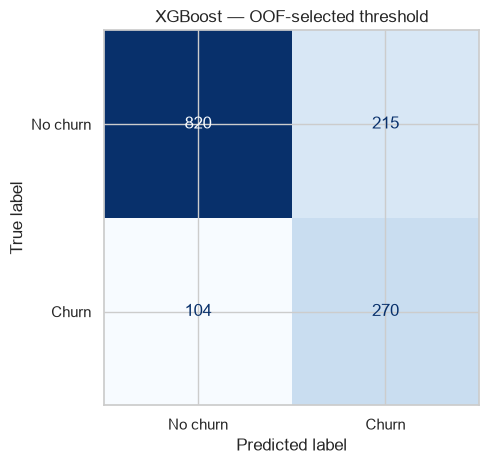

In [14]:
selected_prob=probs[selected_name]; selected_pred=(selected_prob>=best_threshold).astype(int)
print(classification_report(y_test,selected_pred,target_names=["No churn","Churn"],zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,selected_pred,display_labels=["No churn","Churn"],cmap="Blues",colorbar=False)
plt.title(f"{selected_name} — OOF-selected threshold"); plt.tight_layout(); plt.show()

## 15. Top 10 feature importance
Tree feature importance is descriptive, not causal.

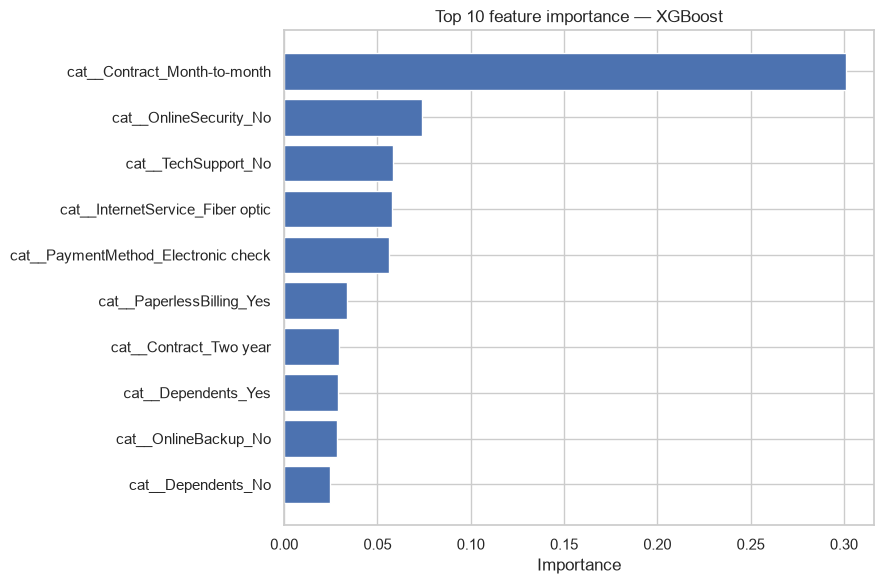

,feature,importance
0,cat__Contract_Month-to-month,0.301069
1,cat__OnlineSecurity_No,0.073814
2,cat__TechSupport_No,0.058542
3,cat__InternetService_Fiber optic,0.058049
4,cat__PaymentMethod_Electronic check,0.056382
5,cat__PaperlessBilling_Yes,0.033914
6,cat__Contract_Two year,0.029468
7,cat__Dependents_Yes,0.028940
8,cat__OnlineBackup_No,0.028383
9,cat__Dependents_No,0.024452


In [15]:
feature_names=selected_model.named_steps["prep"].get_feature_names_out()
importance=pd.DataFrame({"feature":feature_names,"importance":selected_model.named_steps["model"].feature_importances_})
importance=importance.sort_values("importance",ascending=False).reset_index(drop=True)
top=importance.head(10).sort_values("importance")
plt.figure(figsize=(9,6)); plt.barh(top.feature,top.importance)
plt.xlabel("Importance"); plt.title(f"Top 10 feature importance — {selected_name}")
plt.tight_layout(); plt.show()
display(importance.head(10))

## 16. CV versus test ROC-AUC and assignment target

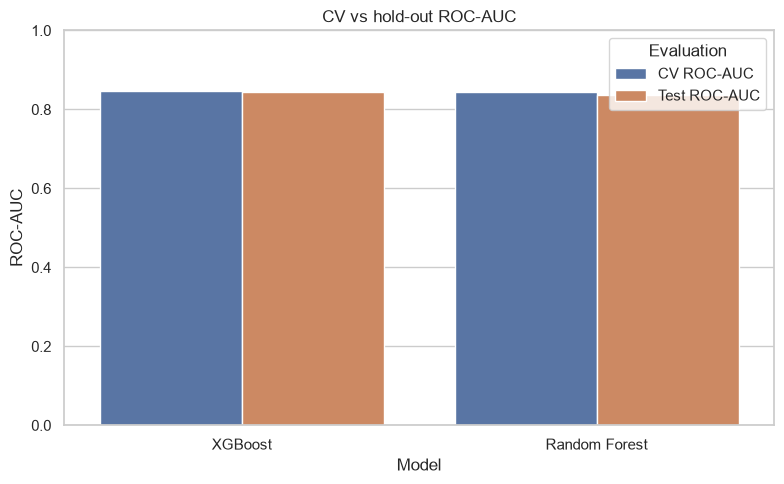

Any test ROC-AUC > 0.80: True


In [16]:
compare=metrics[["Model","CV ROC-AUC","Test ROC-AUC"]].melt(id_vars="Model",var_name="Evaluation",value_name="ROC-AUC")
plt.figure(figsize=(8,5)); sns.barplot(data=compare,x="Model",y="ROC-AUC",hue="Evaluation")
plt.ylim(0,1); plt.title("CV vs hold-out ROC-AUC"); plt.tight_layout(); plt.show()
print("Any test ROC-AUC > 0.80:",bool((metrics["Test ROC-AUC"]>.80).any()))

## 17. Export evaluation outputs

In [17]:
os.makedirs("outputs",exist_ok=True)
metrics.to_csv("outputs/model_metrics.csv",index=False)
importance.to_csv("outputs/feature_importance.csv",index=False)
thresholds.to_csv("outputs/training_oof_threshold_analysis.csv",index=False)
pd.DataFrame({"actual_churn":y_test.to_numpy(),
 "random_forest_probability":probs["Random Forest"],"random_forest_prediction_0_50":preds["Random Forest"],
 "xgboost_probability":probs["XGBoost"],"xgboost_prediction_0_50":preds["XGBoost"]
}).to_csv("outputs/test_predictions.csv",index=False)
print("Exported:",sorted(os.listdir("outputs")))

Exported: ['.gitkeep', 'feature_importance.csv', 'model_metrics.csv', 'test_predictions.csv', 'training_oof_threshold_analysis.csv']


## 18. Business interpretation and limitations
- **Recall** indicates how many actual churners were identified; higher recall may increase unnecessary retention offers.
- **Precision** indicates the share of flagged customers who actually churned.
- **ROC-AUC** measures ranking quality across thresholds, not business value by itself.
- Threshold choice should reflect retention campaign costs and the cost of missed churners.
- Historical customer behavior and service offerings may change over time.
- SMOTE creates synthetic examples; compare it with class weighting and non-resampled baselines before production use.
- Feature importance is associative, not causal.
- Report the measured test score; do not fabricate a result to meet the >0.80 target.
